Jacob Tran  
Professor Morales  
PHYS 434  
3 November 2026  
Lab 5 Write-Up  

## Project Proposal  

For this project my partner and I are using data from the SDSS black hole mapper, but different datasets. The data I will be observing is from this Value-Added Catalogue:  
https://www.sdss.org/dr18/data_access/value-added-catalogs/?vac_id=10030  
Which contains a table of parameters for 3082 different quasars. The question that I will be testing with this data is: How much of the observed optical spectrum is from the quasar itself versus the surrounding host galaxy?  
The linked data catalogue also contains a table with CaII-H and Hb indices that will help distinguish when spectral emissions are dominated by their host galaxies versus their active galactic nuclei. I will use this table to subtract the host galaxy contributions to the spectra and isolate the AGN spectra. 

In [1]:
%matplotlib inline
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import scipy
from scipy import stats
import h5py
import pandas as pd
from astropy.io import fits

from astropy.visualization import astropy_mpl_style
plt.style.use(astropy_mpl_style)

from astropy.utils.data import download_file
from astropy.io import fits

plt.rcParams["figure.figsize"] = (8,6)

Number of rows: 83120
['FIELD', 'MJD', 'OBS', 'MJD_FINAL', 'MJD_LIST', 'TAI_LIST', 'RUN2D', 'RUN1D', 'DESIGNS', 'CONFIGS', 'NEXP', 'EXPTIME', 'TARGET_INDEX', 'FIBERID_LIST', 'SPEC_FILE', 'PROGRAMNAME', 'SURVEY', 'CADENCE', 'FIRSTCARTON', 'CARTON_TO_TARGET_PK', 'SDSS5_TARGET_FLAGS', 'OBJTYPE', 'CATALOGID', 'CATALOGID_V0', 'CATALOGID_V0P5', 'SDSS_ID', 'SPECOBJID', 'CALIBFLUX', 'CALIBFLUX_IVAR', 'OPTICAL_PROV', 'MAG', 'PSFMAG', 'FIBER2MAG', 'CATDB_MAG', 'GAIA_G_MAG', 'GRI_GAIA_TRANSFORM', 'BP_MAG', 'RP_MAG', 'GAIA_ID', 'WISE_MAG', 'TWOMASS_MAG', 'GUVCAT_MAG', 'EBV', 'EBV_TYPE', 'FIBER_RA', 'FIBER_DEC', 'PLUG_RA', 'PLUG_DEC', 'RACAT', 'DECCAT', 'COORD_EPOCH', 'PMRA', 'PMDEC', 'PARALLAX', 'RA_LIST', 'DEC_LIST', 'DELTA_RA_LIST', 'DELTA_DEC_LIST', 'FIBER_OFFSET', 'XFOCAL', 'YFOCAL', 'ZOFFSET', 'LAMBDA_EFF', 'BLUEFIBER', 'HEALPIX', 'HEALPIXGRP', 'HEALPIX_PATH', 'FIELDQUALITY', 'EXP_DISP_MED', 'FIELDSN2', 'FIELDSNR2G_LIST', 'FIELDSNR2R_LIST', 'FIELDSNR2I_LIST', 'SPEC1_G', 'SPEC1_R', 'SPEC1_I', 

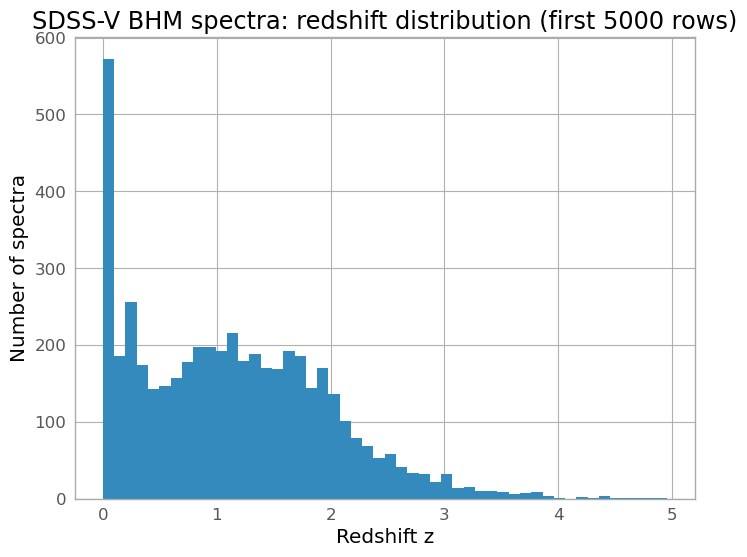

In [2]:
with fits.open("spAll-v6_1_3-allepoch.fits", memmap=True) as hdul:
    hdu = hdul[1]
    print("Number of rows:", hdu.header["NAXIS2"])
    print(hdu.columns.names)              # all column names (no data loaded yet)

    data = hdu.data[:5000]                # only the first 5000 rows
    z = np.array(data["Z"])               # change "Z" if the column has a different name

fig, ax = plt.subplots()
ax.hist(z[z > 0], bins=50)
ax.set_xlabel("Redshift z")
ax.set_ylabel("Number of spectra")
ax.set_title("SDSS-V BHM spectra: redshift distribution (first 5000 rows)")
plt.show()

## Imported the data sample hgindices_jtran360 from SDSS DR20

In [54]:
df = pd.read_csv('hgindices_jtran360.csv')['fhb_c4750']

print(df) 


0       0.996
1       0.998
2       0.966
3       1.033
4       0.979
        ...  
3077    0.993
3078    0.951
3079    1.065
3080    0.968
3081    1.050
Name: fhb_c4750, Length: 3082, dtype: float64


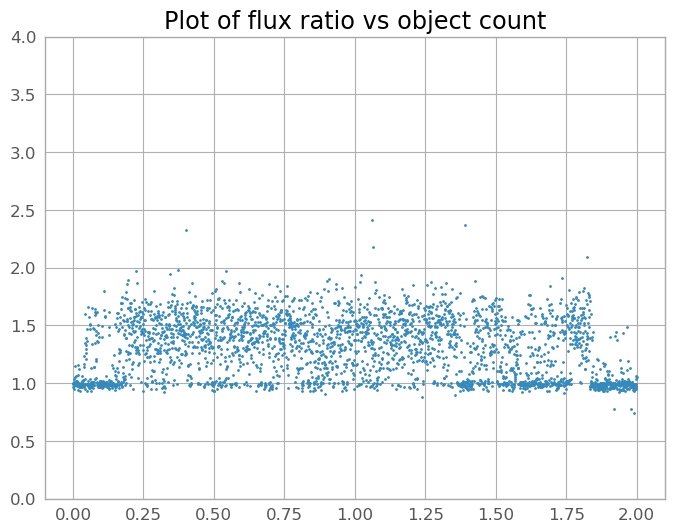

In [68]:
def scatter_plot(x, y, title):
    fig, ax = plt.subplots(1, 1)
    ax.scatter(x, y, s=1)
    plt.ylim(0,4)
    ax.set_title(title)
    
    plt.show()

size = df.size

x = np.linspace(0,2,size)

scatter_plot(x, df, 'Plot of flux ratio vs object count')
